In [3]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# Windows-only common workaround for libiomp duplicate init crashes:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import time
from torch.nn.utils.stateless import functional_call  # <--- required
import matplotlib.pyplot as plt
from GLAdSSNOptimizer import GlAdSSNOptimizer
from torch.func import functional_call
import math
from utils import make_param_vector_interface, hessian_norm_penalty


device = torch.device("cpu")  # change to "cuda" if you want and have GPU
torch.manual_seed(26)


# Set up regression problem and define neural network

In [4]:
device = torch.device("cpu")

N = 100
X = torch.rand(N, 2, device=device) * 2 * math.pi
Y = (
    torch.sin(X[:, 0]) * torch.cos(X[:, 1])
    + 0.2 * torch.sin(2 * X[:, 0] + X[:, 1])
    + 0.1 * X[:, 0] * X[:, 1]
)
Y = Y + 0.05 * torch.randn_like(Y)
Y = Y.unsqueeze(1)

no_of_power_iterations = (
    5  # no of power iterations (for Hessian operator norm estimation)
)
penalty_coefficient = 1

dataset = list(zip(X, Y))
batch_size = len(dataset)  # full batch


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 16)
        self.fc2 = nn.Linear(16, 16)
        self.fc3 = nn.Linear(16, 1)

    def forward(self, x):
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        return self.fc3(x)


all_histories = {}  # list to store method labels for plotting


# Accuracy estimation

In [5]:
def simulate_dataset(N, device=device, noise_std=0.05):
    X = torch.rand(N, 2, device=device) * 2 * math.pi
    Y = (
        torch.sin(X[:, 0]) * torch.cos(X[:, 1])
        + 0.2 * torch.sin(2 * X[:, 0] + X[:, 1])
        + 0.1 * X[:, 0] * X[:, 1]
    )
    Y = Y + noise_std * torch.randn_like(Y)
    Y = Y.unsqueeze(1)
    return list(zip(X, Y))


def evaluate_regression_accuracy(model, dataset_to_test, tolerance=0.001, batch_size=None):
    was_training = model.training
    model.eval()

    if batch_size is None:
        batch_size = len(dataset_to_test)

    total_correct = 0.0
    total_sq_error = 0.0
    total_points = 0

    with torch.no_grad():
        for i in range(0, len(dataset_to_test), batch_size):
            batch = dataset_to_test[i : i + batch_size]
            xb = torch.stack([b[0] for b in batch]).to(device)
            yb = torch.stack([b[1] for b in batch]).to(device)

            pred = model(xb)
            err = pred - yb

            total_correct += (err.abs() <= tolerance).float().sum().item()
            total_sq_error += err.pow(2).sum().item()
            total_points += yb.numel()

    if was_training:
        model.train()

    accuracy = total_correct / total_points
    mse = total_sq_error / total_points
    return accuracy, mse

# GLAd-SSN trainer

In [6]:
def train_with_gladssn(
    epochs=50,
    update_freq=1,  # lazy Hessian, Hessian is updated every update_freq steps
    lambda0=1.0,
    m=25,  # max number of adaptive steps
    print_freq=10,
    return_model=False,
    symmetrize=True,
):
    # Model
    model = Net().to(device)
    model.train()
    for p in model.parameters():
        p.requires_grad_(True)

    # Vectorization helpers
    pack, vec_to_param_dict, assign, _ = make_param_vector_interface(
        model, trainable_only=True
    )

    # Optimizer
    optimizer = GlAdSSNOptimizer(
        model.parameters(),
        lambda0=lambda0,
        m=m,
        number_of_steps_to_freeze=update_freq,
        symmetrize=symmetrize,
    )

    # Batches
    Xb = X.to(device)
    Yb = Y.to(device)

    v0 = torch.ones_like(Xb)  # initialisation for Hessian penalty function

    # Define the objective as a function of the flat parameter vector
    def loss_from_vec(vec):
        params_dict = vec_to_param_dict(vec)
        pred = functional_call(model, params_dict, Xb)
        loss_main = F.mse_loss(pred, Yb)

        pen, _ = hessian_norm_penalty(
            model,
            params_dict,
            Xb,
            v0,
            coeff=penalty_coefficient,
            K=no_of_power_iterations,
        )
        return loss_main + pen

    # Training loop
    loss_list = []
    time_list = []
    hessian_norm_list = []
    grad_list = []
    lambda_k_list = []

    t0 = time.time()

    for epoch in range(epochs):
        # one full-batch optimiser step
        fk, gk, lambda_k = optimizer.step(loss_from_vec, pack=pack, assign=assign)

        # log "current" loss after the update (still simple, but correct)
        vec_now = pack().detach().requires_grad_(True)
        params_now = vec_to_param_dict(vec_now)

        pred = functional_call(model, params_now, Xb)
        loss_main = F.mse_loss(pred, Yb)
        loss_penalty, norm_of_hessian = hessian_norm_penalty(
            model,
            params_now,
            Xb,
            v0,
            coeff=penalty_coefficient,
            K=no_of_power_iterations,
        )

        loss_val = (loss_main + loss_penalty).detach().item()

        loss_list.append(loss_val)
        hessian_norm_list.append(norm_of_hessian.detach().item())
        grad_list.append(gk.norm().cpu().item())
        time_list.append(time.time() - t0)
        lambda_k_list.append(lambda_k)

        if print_freq and (epoch + 1) % print_freq == 0:
            print(
                f"[GLAd-SSN] Epoch {epoch + 1:03d}/{epochs} loss={loss_val:.6f} Hessian norm={hessian_norm_list[-1]:.4f} t={time_list[-1]:.2f}s"
            )

    if return_model:
        return model, loss_list, time_list, grad_list, hessian_norm_list, lambda_k_list
    return loss_list, time_list, grad_list, hessian_norm_list, lambda_k_list


# Adam trainer

In [7]:
def train_with_adam(
    epochs=20,
    lr=7 * 1e-4,
    batch_size=None,
    print_freq=100,
    return_model=False,
):
    model = Net().to(device)
    model.train()

    opt = torch.optim.Adam(model.parameters(), lr=lr)

    if batch_size is None:
        batch_size = len(dataset)

    loss_list = []
    time_list = []
    hessian_norm_list = []  # avg Hessian per epoch
    grad_list = []  # avg grad norm per epoch
    gradmax_list = []  # max grad norm per epoch

    t0 = time.time()

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=0.5, patience=5, threshold=1 * 1e-5, min_lr=1e-6
    )

    for epoch in range(epochs):
        total_loss = 0.0

        sum_norm_of_hessians = 0.0
        max_norm_of_hessians = 0.0

        sum_grad_norms = 0.0
        max_grad_norm = 0.0

        num_batches = 0
        random.shuffle(dataset)

        for i in range(0, len(dataset), batch_size):
            batch = dataset[i : i + batch_size]
            xb = torch.stack([b[0] for b in batch]).to(device)  # (B,2)
            yb = torch.stack([b[1] for b in batch]).to(device)  # (B,1)

            # --- your penalty needs a params_dict because it uses functional_call ---
            params_now = dict(model.named_parameters())  # simplest form
            v0 = torch.ones_like(
                xb
            )  # initialisation for Hessian penalty function ; shape (B,2)

            opt.zero_grad(set_to_none=True)

            # main loss
            pred = model(xb)
            loss_main = F.mse_loss(pred, yb)

            # penalty loss
            loss_penalty, norm_of_hessian = hessian_norm_penalty(
                model,
                params_now,
                xb,
                v0,
                coeff=penalty_coefficient,
                K=no_of_power_iterations,
            )

            loss = loss_main + loss_penalty
            loss.backward()

            # Log gradient norm
            with torch.no_grad():
                g2 = torch.zeros((), device=xb.device)
                for p in model.parameters():
                    if p.grad is not None:
                        g2 += p.grad.pow(2).sum()
                grad_norm = torch.sqrt(g2).item()

            opt.step()

            # accumulate stats
            total_loss += float(loss.detach()) * xb.size(0)

            norm_of_hessian_val = float(norm_of_hessian.detach())
            sum_norm_of_hessians += norm_of_hessian_val
            max_norm_of_hessians = max(max_norm_of_hessians, norm_of_hessian_val)

            sum_grad_norms += grad_norm
            max_grad_norm = max(max_grad_norm, grad_norm)

            num_batches += 1

        avg_loss = total_loss / len(dataset)
        scheduler.step(avg_loss)

        loss_list.append(avg_loss)
        time_list.append(time.time() - t0)

        average_hessian_norm = sum_norm_of_hessians / max(1, num_batches)
        hessian_norm_list.append(average_hessian_norm)

        average_grad_norm = sum_grad_norms / max(1, num_batches)
        grad_list.append(average_grad_norm)
        gradmax_list.append(max_grad_norm)

        if print_freq and (epoch + 1) % print_freq == 0:
            print(
                f"[Adam] Epoch {epoch + 1}/{epochs} loss={avg_loss:.6f}  "
                f"Hessian norm (max)={max_norm_of_hessians:.4f} Hessian norm (avg)={average_hessian_norm:.4f}  "
                f"Grad norm (max)={max_grad_norm:.4e} Grad norm (avg)={average_grad_norm:.4e}"
            )

    if return_model:
        return model, loss_list, time_list, grad_list, hessian_norm_list
    return loss_list, time_list, grad_list, hessian_norm_list


## Train with various optimizers

In [8]:
accuracies_train = []
accuracies_test = []
print("Training with Adam...")
result = train_with_adam(epochs=900000, lr=1e-4, print_freq=10000, return_model=True) # 900000
model_adam = result[0]
all_histories["Adam"] = result[1:]

Training with Adam...


/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-essen.sciebo.de/Code/Lazy Hessian code/NN/utils.py:47: FutureWarning: `torch.nn.utils.stateless.functional_call` is deprecated as of PyTorch 2.0 and will be removed in a future version of PyTorch. Please use `torch.func.functional_call` instead which is a drop-in replacement.
  y = functional_call(model, params_dict, xb).sum()


[Adam] Epoch 10000/900000 loss=0.011288  Hessian norm (max)=1.0007 Hessian norm (avg)=1.0007  Grad norm (max)=6.9767e-03 Grad norm (avg)=6.9767e-03
[Adam] Epoch 20000/900000 loss=0.003376  Hessian norm (max)=1.0009 Hessian norm (avg)=1.0009  Grad norm (max)=7.9570e-04 Grad norm (avg)=7.9570e-04
[Adam] Epoch 30000/900000 loss=0.001935  Hessian norm (max)=1.0006 Hessian norm (avg)=1.0006  Grad norm (max)=5.0279e-04 Grad norm (avg)=5.0279e-04
[Adam] Epoch 40000/900000 loss=0.001585  Hessian norm (max)=1.0005 Hessian norm (avg)=1.0005  Grad norm (max)=3.4309e-04 Grad norm (avg)=3.4309e-04
[Adam] Epoch 50000/900000 loss=0.001474  Hessian norm (max)=1.0004 Hessian norm (avg)=1.0004  Grad norm (max)=3.4447e-04 Grad norm (avg)=3.4447e-04
[Adam] Epoch 60000/900000 loss=0.001399  Hessian norm (max)=1.0004 Hessian norm (avg)=1.0004  Grad norm (max)=5.8444e-04 Grad norm (avg)=5.8444e-04
[Adam] Epoch 70000/900000 loss=0.001345  Hessian norm (max)=1.0004 Hessian norm (avg)=1.0004  Grad norm (max)=1.

In [9]:
## train accuracy adam
train_acc, train_mse = evaluate_regression_accuracy(
    model_adam,
    dataset,
    tolerance=0.10,
    batch_size=batch_size,
)   
print(f"Adam, train accuracy: {train_acc}, train mse: {train_mse}")

#test accuracy adam
simulated_test_dataset = simulate_dataset(N=1000, device=device, noise_std=0.05)
test_acc, test_mse = evaluate_regression_accuracy(
    model_adam,
    simulated_test_dataset,
    tolerance=0.10,
    batch_size=batch_size,
)   
print(f"Adam, test accuracy: {test_acc}, test mse: {test_mse}")

Adam, train accuracy: 1.0, train mse: 0.0010936087369918823
Adam, test accuracy: 0.783, test mse: 0.008262274146080018


In [10]:
print("\nTraining with GLAd-SSN...")
result = train_with_gladssn(epochs=13000, update_freq=1, return_model=True) #10000
model_glad = result[0]
all_histories["GLAd-SSN"] = result[1:]



Training with GLAd-SSN...
[GLAd-SSN] Epoch 010/13000 loss=0.255874 Hessian norm=0.5600 t=2.72s
[GLAd-SSN] Epoch 020/13000 loss=0.112305 Hessian norm=1.0008 t=5.30s
[GLAd-SSN] Epoch 030/13000 loss=0.063491 Hessian norm=0.9965 t=7.89s
[GLAd-SSN] Epoch 040/13000 loss=0.049312 Hessian norm=1.0011 t=10.40s
[GLAd-SSN] Epoch 050/13000 loss=0.039760 Hessian norm=1.0030 t=12.93s
[GLAd-SSN] Epoch 060/13000 loss=0.031561 Hessian norm=0.9857 t=15.46s
[GLAd-SSN] Epoch 070/13000 loss=0.028347 Hessian norm=0.9955 t=17.98s
[GLAd-SSN] Epoch 080/13000 loss=0.024803 Hessian norm=0.9961 t=20.50s
[GLAd-SSN] Epoch 090/13000 loss=0.022657 Hessian norm=0.9994 t=23.04s
[GLAd-SSN] Epoch 100/13000 loss=0.020042 Hessian norm=0.9975 t=25.57s
[GLAd-SSN] Epoch 110/13000 loss=0.018476 Hessian norm=0.9994 t=28.11s
[GLAd-SSN] Epoch 120/13000 loss=0.017930 Hessian norm=1.0000 t=30.65s
[GLAd-SSN] Epoch 130/13000 loss=0.017629 Hessian norm=0.9996 t=33.20s
[GLAd-SSN] Epoch 140/13000 loss=0.017406 Hessian norm=1.0000 t=36.

In [11]:
## train accuracy glad
train_acc, train_mse = evaluate_regression_accuracy(
    model_glad,
    dataset,
    tolerance=0.10,
    batch_size=batch_size,
)   
print(f"Glad, train accuracy: {train_acc}, train mse: {train_mse}")

#test accuracy glad
simulated_test_dataset = simulate_dataset(N=1000, device=device, noise_std=0.05)
test_acc, test_mse = evaluate_regression_accuracy(
    model_glad,
    simulated_test_dataset,
    tolerance=0.10,
    batch_size=batch_size,
)   
print(f"Glad, test accuracy: {test_acc}, test mse: {test_mse}")

Glad, train accuracy: 0.94, train mse: 0.0031901654601097108
Glad, test accuracy: 0.677, test mse: 0.015646260142326354


In [12]:
# # Lazy
# list_of_lazy_frequencies = ["5", "100", "1000", "2500", "5000"]
# for lazy_freq in list_of_lazy_frequencies:
#     print("Training with GLAdSSN with lazy frequency", lazy_freq)
#     all_histories[f"GLAd-SSN m={lazy_freq}"] = train_with_gladssn(
#         epochs=10000, update_freq=int(lazy_freq), print_freq=1000
#     )
# Lazy
models_lazy = [1,2,3,4,5]
list_of_lazy_frequencies = ["5", "100", "1000", "2500", "5000"]
counter = 0
for lazy_freq in list_of_lazy_frequencies:
    print("Training with GLAdSSN with lazy frequency", lazy_freq)
    result = train_with_gladssn(
        epochs=13000, update_freq=int(lazy_freq), print_freq=1000, return_model=True) # 10000
    models_lazy[counter] = result[0]
    all_histories[f"GLAd-SSN m={lazy_freq}"] = result[1:]
    counter = counter+1

Training with GLAdSSN with lazy frequency 5
[GLAd-SSN] Epoch 1000/13000 loss=0.013848 Hessian norm=1.0009 t=55.34s
[GLAd-SSN] Epoch 2000/13000 loss=0.010209 Hessian norm=1.0009 t=110.96s
[GLAd-SSN] Epoch 3000/13000 loss=0.006664 Hessian norm=1.0012 t=166.97s
[GLAd-SSN] Epoch 4000/13000 loss=0.004755 Hessian norm=1.0013 t=223.52s
[GLAd-SSN] Epoch 5000/13000 loss=0.004237 Hessian norm=1.0013 t=280.26s
[GLAd-SSN] Epoch 6000/13000 loss=0.004017 Hessian norm=1.0013 t=336.88s
[GLAd-SSN] Epoch 7000/13000 loss=0.003838 Hessian norm=1.0013 t=393.54s
[GLAd-SSN] Epoch 8000/13000 loss=0.003596 Hessian norm=1.0012 t=450.68s
[GLAd-SSN] Epoch 9000/13000 loss=0.003454 Hessian norm=1.0012 t=508.03s
[GLAd-SSN] Epoch 10000/13000 loss=0.003359 Hessian norm=1.0012 t=565.27s
[GLAd-SSN] Epoch 11000/13000 loss=0.003229 Hessian norm=1.0011 t=622.44s
[GLAd-SSN] Epoch 12000/13000 loss=0.002993 Hessian norm=1.0011 t=679.63s
[GLAd-SSN] Epoch 13000/13000 loss=0.002890 Hessian norm=1.0011 t=737.05s
Training with GLA

In [13]:
## computing accuracies
counter = 0
for lazy_freq in list_of_lazy_frequencies:
    model = models_lazy[counter]    
    train_acc, train_mse = evaluate_regression_accuracy(
    model,
    dataset,
    tolerance=0.10,
    batch_size=batch_size,
    )   

    simulated_test_dataset = simulate_dataset(N=1000, device=device, noise_std=0.05)
    test_acc, test_mse = evaluate_regression_accuracy(
    model,
    simulated_test_dataset,
    tolerance=0.10,
    batch_size=batch_size,
)   
    print(f" glad lazy freq: {lazy_freq}, train accuracy: {train_acc}, train mse: {train_mse}")
    print(f" glad lazy freq: {lazy_freq}, test accuracy: {test_acc}, test mse: {test_mse}")
    counter= counter+1


 glad lazy freq: 5, train accuracy: 0.94, train mse: 0.0028848564624786377
 glad lazy freq: 5, test accuracy: 0.728, test mse: 0.011214888751506806
 glad lazy freq: 100, train accuracy: 0.96, train mse: 0.0026548284292221068
 glad lazy freq: 100, test accuracy: 0.752, test mse: 0.009714456140995026
 glad lazy freq: 1000, train accuracy: 0.63, train mse: 0.010098528861999512
 glad lazy freq: 1000, test accuracy: 0.578, test mse: 0.0213224595785141
 glad lazy freq: 2500, train accuracy: 0.83, train mse: 0.005326784253120422
 glad lazy freq: 2500, test accuracy: 0.643, test mse: 0.015113878726959228
 glad lazy freq: 5000, train accuracy: 0.49, train mse: 0.02190058708190918
 glad lazy freq: 5000, test accuracy: 0.47, test mse: 0.031777570962905885


In [14]:
# Save only the numeric series used by the plots.
import pickle

plot_histories = {}
for label, history in all_histories.items():
    saved_history = {
        "loss": list(history[0]),
        "time": list(history[1]),
        "grad_norm": list(history[2]),
        "hessian_norm": list(history[3]),
    }
    if len(history) > 4:
        saved_history["lambda"] = list(history[4])
    plot_histories[label] = saved_history

with open("nn_results.pkl", "wb") as result_file:
    pickle.dump({"histories": plot_histories, "labels": list(all_histories)}, result_file)

print("Saved plotting data to nn_results.pkl")

Saved plotting data to nn_results.pkl


# Code for plotting

In [15]:
# colors = ["purple", '#993404', '#CC4C02', '#EC7014', '#FEC44F', '#FEE391']
# colors = ["#E8601C", "#9A709E", "#88A5DD", "#8DCBE4", "#C2E3D2"]

adam_color = "#E8601C"
gladssn_color = "#9B8AC4"
gladssn_lazy_1_color = "#88A5DD"
gladssn_lazy_2_color = "#8DCBE4"
gladssn_lazy_3_color = "#C2E3D2"
gladssn_lazy_4_color = "#DDECBF"
gladssn_lazy_5_color = "#F2E1D0"

colors = [
    adam_color,
    gladssn_color,
    gladssn_lazy_1_color,
    gladssn_lazy_2_color,
    gladssn_lazy_3_color,
    gladssn_lazy_4_color,
    gladssn_lazy_5_color,
]

line_widths = [1.0] * len(list(all_histories.keys()))
line_styles = ["-"] * len(list(all_histories.keys()))

marker_cycle = [
    "None",   # None Adam
    "^",   # triangle up GladSSN
    "D",   # diamond GladSSN second
    "x",   # x GladSSN third
    "v",   # triangle down GladSSN fourth
    "h",   # hexagon GladSSN fifth
    "1",   # trianglular shape GladSSN sixth
]

labels = list(all_histories.keys())

In [16]:
print(all_histories.keys())



dict_keys(['Adam', 'GLAd-SSN', 'GLAd-SSN m=5', 'GLAd-SSN m=100', 'GLAd-SSN m=1000', 'GLAd-SSN m=2500', 'GLAd-SSN m=5000'])


# Plot graphs

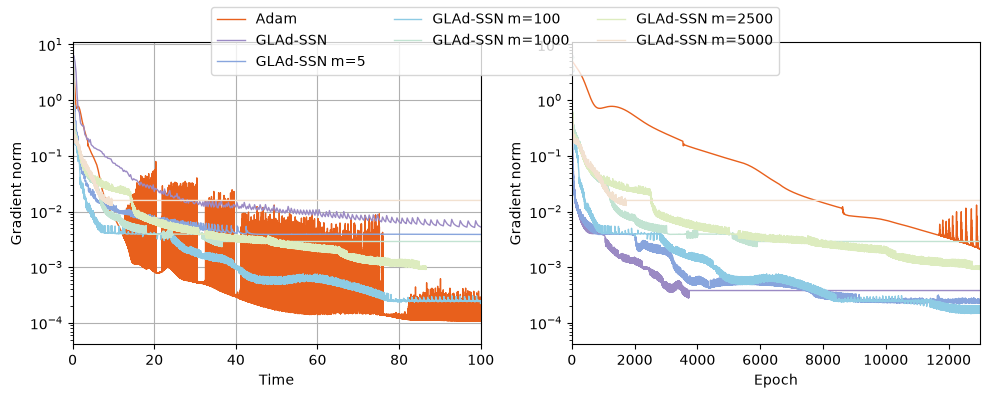

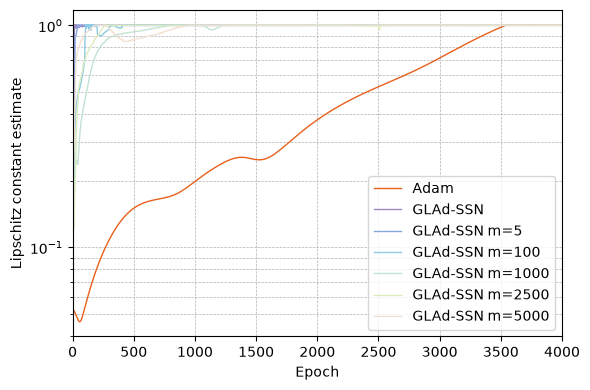

In [17]:
from matplotlib import axes


def plot_graphs(
    list_of_times,
    list_of_grads,
    list_of_labels,
    number_of_methods,
    y_label,
    line_styles,
    which_measure
):
    markevery_numbers = [15000, 15000, 15000, 15000, 15000, 15000, 15000]
    if number_of_methods is None:
        number_of_methods = len(list_of_times)
    marker_size = 2
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # 2x2 grid
    axes = axes.flatten()  # turn into a simple list: axes[0], axes[1], axes[2], axes[3]
    for i in range(number_of_methods):
        # if labels[i] == "Adam":
            # skip Adam
            # continue
        axes[0].semilogy(
            list_of_times[i],
            list_of_grads[i],
            label=labels[i],
            color=colors[i],
            linewidth=1,
            linestyle=line_styles[i],
            # marker=marker_cycle[i],
            markersize=2*marker_size,
            markevery=markevery_numbers[i],
        )
    axes[0].set_xlabel("Time")
    axes[0].set_ylabel(y_label)
    axes[0].set_xlim(0, 100)
    # axes[0].legend()
    axes[0].grid(True)

    # Now plot epoch vs grad norm
    # plt.subplot(1, 2, 2)
    for i in range(number_of_methods):
        axes[1].semilogy(
            list_of_grads[i],
            label=labels[i],
            color=colors[i],
            # linewidth=line_widths[i],
            linewidth=1,
            linestyle=line_styles[i],
            marker=marker_cycle[i],
            markersize=marker_size,
            markevery=markevery_numbers[i],
        )
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel(y_label)
    axes[1].set_xlim(0, 13000)
    # Shared legend
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="upper center", ncol=3)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(
        "plot_NN_" + which_measure + ".pdf"
    )  # creates a PGF file (LaTeX/PGF code)
    plt.show()

def plot_penalty(
    list_of_times,
    list_of_grads,
    list_of_labels,
    number_of_methods,
    y_label,
    line_styles,
    which_measure
):
    markevery_numbers = [100000, 15, 50, 50, 50, 50, 50]
    if number_of_methods is None:
        number_of_methods = len(list_of_times)
    marker_size = 2
    plt.figure(figsize=(6, 4))

    for i in range(number_of_methods):
        plt.semilogy(
            list_of_grads[i],
            label=labels[i],
            color=colors[i],
            # linewidth=line_widths[i],
            linewidth=1,
            linestyle=line_styles[i],
            # marker=marker_cycle[i],
            markersize=marker_size,
            markevery=markevery_numbers[i],
        )
    plt.xlim(0,4000)
    plt.xlabel("Epoch")
    plt.ylabel(y_label)
    plt.grid(True, which="both", linestyle="--", linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        "plot_NN_" + which_measure + ".pdf"
    )  # creates a PGF file (LaTeX/PGF code)
    plt.show()
all_methods = list(all_histories.keys())
times_list = [all_histories[m][1] for m in all_methods]
grads_list = [all_histories[m][2] for m in all_methods]
hess_op_norm_list = [all_histories[m][3] for m in all_methods]
lambdas_list = [all_histories[m][4] for m in all_methods if m != "Adam"]

without_adam_times_list = [all_histories[m][1] for m in all_methods if m != "Adam"]


plot_graphs(
    times_list,
    grads_list,
    all_methods,
    None,
    "Gradient norm",
    line_styles,
    which_measure="grad_norm",
)
plot_penalty(
    times_list,
    hess_op_norm_list,
    all_methods,
    None,
    "Lipschitz constant estimate",
    line_styles,
    which_measure="hess_op_norm",
)
# plot_graphs(without_adam_times_list, lambdas_list, all_methods.remove("Adam"), 4, "Lambda", line_styles)